<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_5/dataset_pbl/pertemuan_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Pertemuan 1**
## **Persiapan Lingkungan**

In [1]:
# Instalasi pustaka hdbscan (tidak tersedia default di sklearn)
!pip install hdbscan

# Import modul
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler, LabelEncoder
import hdbscan

## **Langkah 2: Definisi Fungsi Visualisasi**
Jalankan fungsi ini agar kita bisa mem-plot hasil clustering dengan warna berbeda.




In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

## **Langkah 3: Membuat Dataset Sintesis**
Dataset terdiri dari 3 buah cluster Gaussian

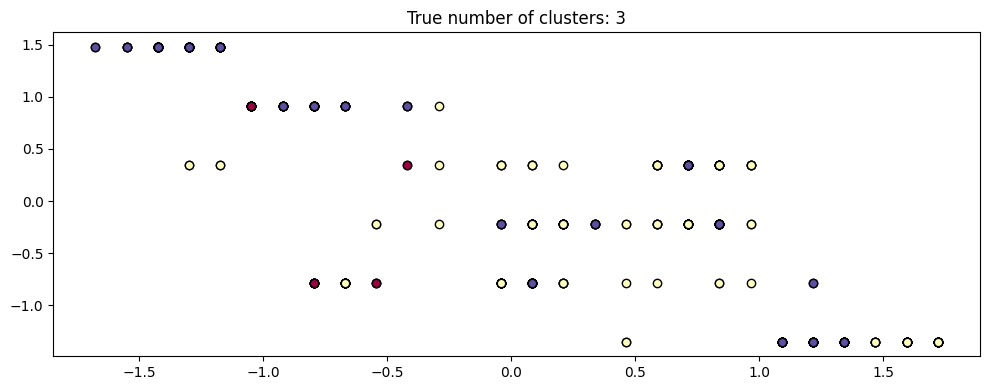

In [3]:
# Memuat dataset Sleep Health
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

# Pilih 2 fitur numerik untuk visualisasi 2D dan standarisasi skalanya
fitur = ['Sleep Duration', 'Stress Level']
X = StandardScaler().fit_transform(df[fitur])

# Label asli dari kolom 'Sleep Disorder' (0: Insomnia, 1: None, 2: Sleep Apnea)
le = LabelEncoder()
labels_true = le.fit_transform(df['Sleep Disorder'].fillna('None'))

plot(X, labels=labels_true, ground_truth=True)

## **Langkah 4: Uji Scale Invariance pada DBSCAN**
Jalankan DBSCAN dengan eps=0.3 pada dataset yang di-scale.


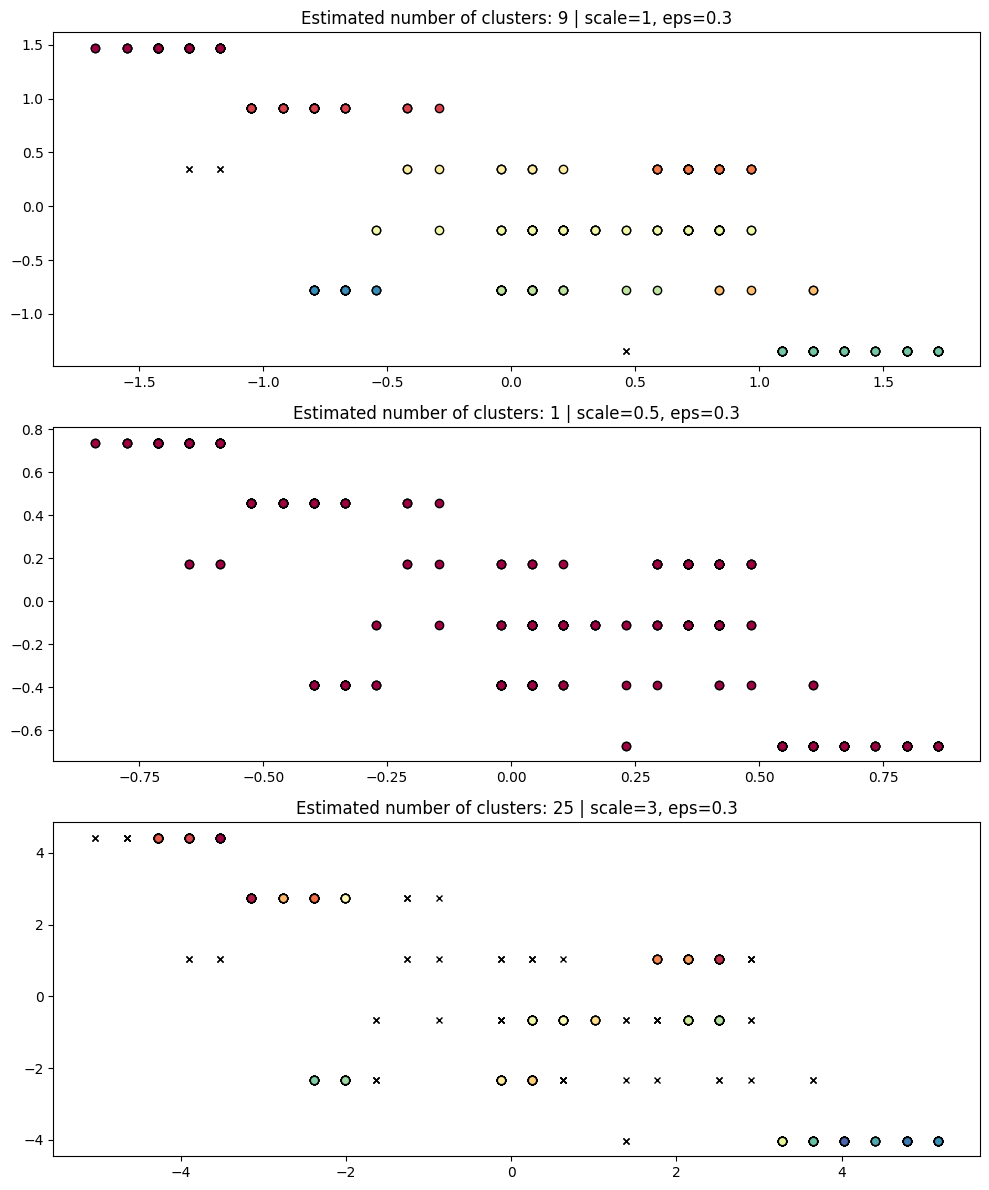

In [4]:
# Jalankan DBSCAN dengan eps=0.3 pada dataset Sleep Health yang di-scale
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])

Perbaiki dengan mengubah eps sesuai skala:

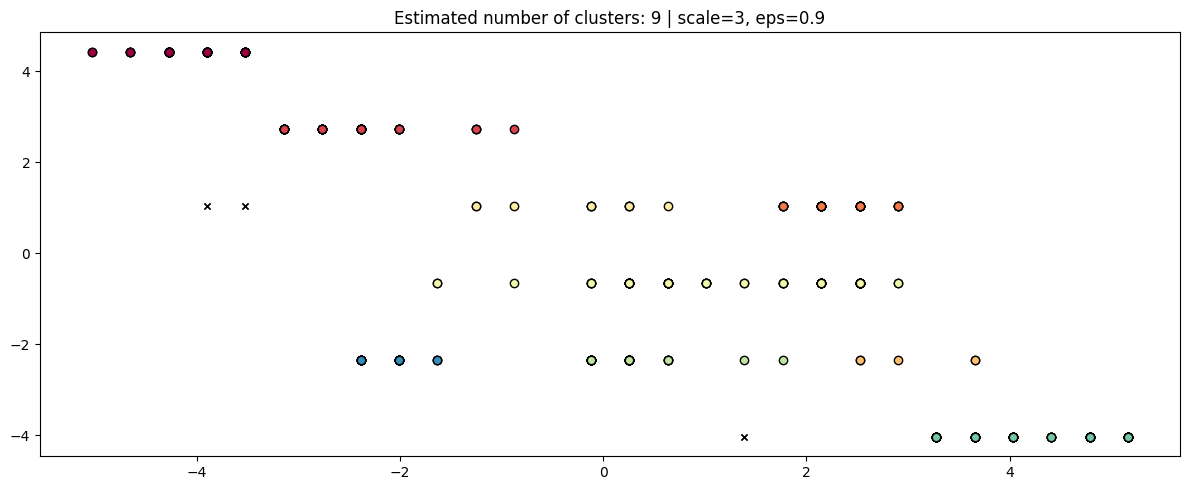

In [5]:
# Perbaiki dengan menyesuaikan eps sebesar 3x (0.3 * 3 = 0.9) untuk skala 3
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)

## **Langkah 5: Bandingkan dengan HDBSCAN (lebih robust)**
Jalankan HDBSCAN pada dataset berskala berbeda.


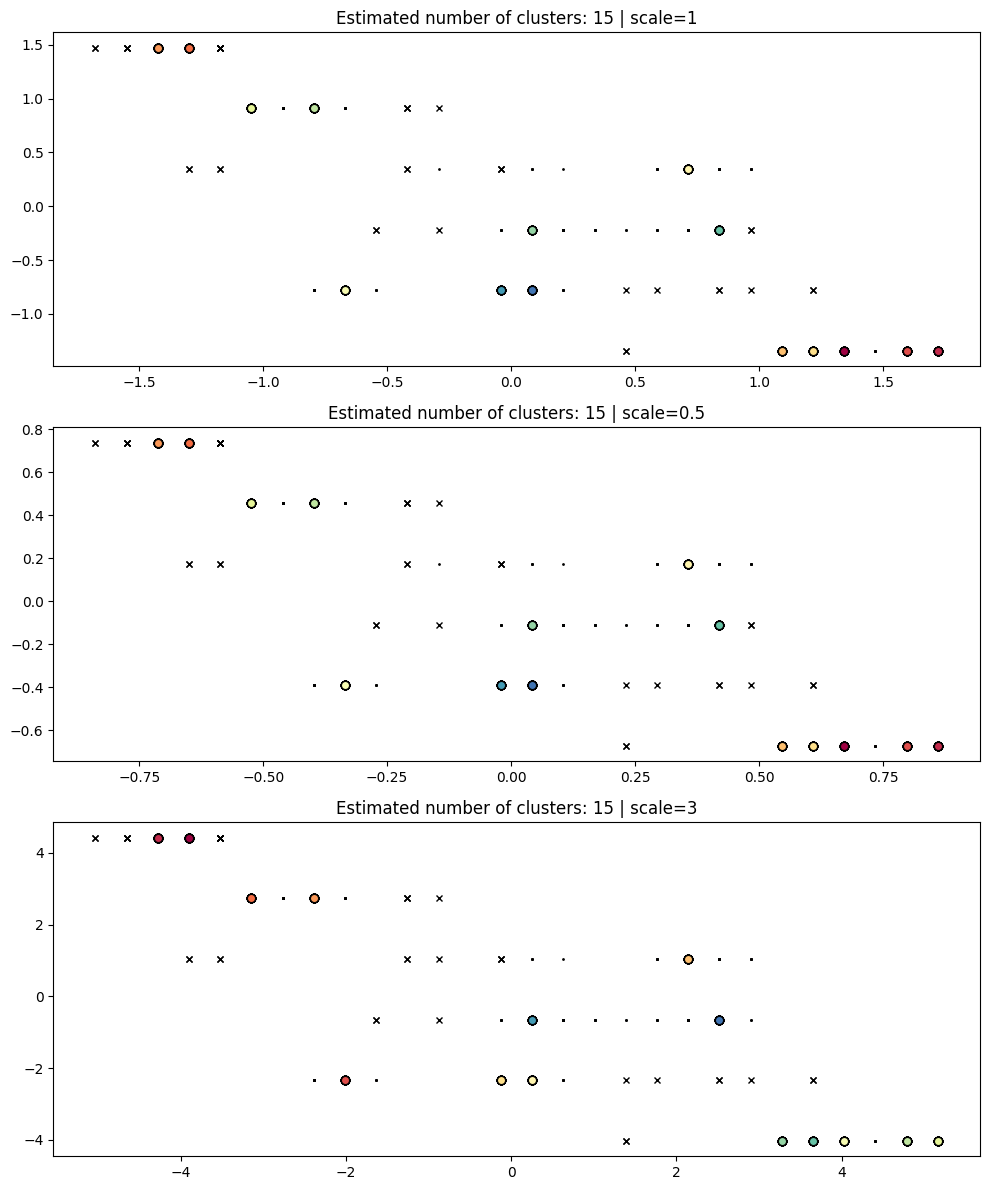

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN(min_cluster_size=10)
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})

## **Langkah 6: Multi-Scale Clustering**
Buat dataset baru dengan kepadatan berbeda

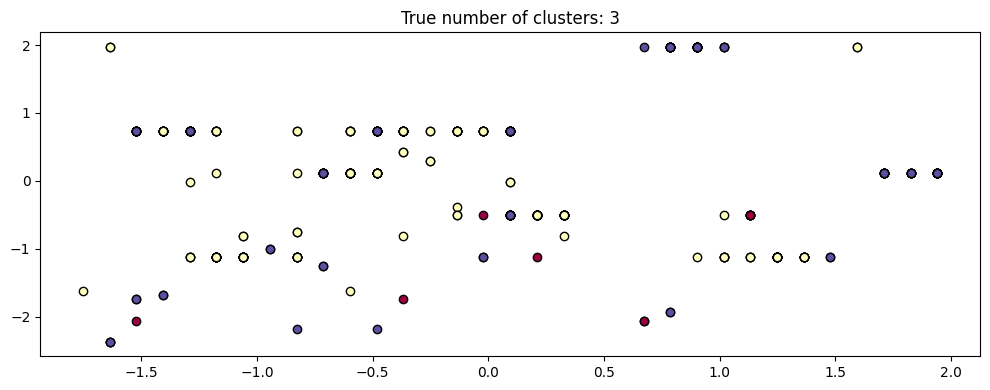

In [8]:
X_multi = StandardScaler().fit_transform(df[['Age', 'Daily Steps']])
plot(X_multi, labels=labels_true, ground_truth=True)

Bandingkan DBSCAN dengan eps berbeda:

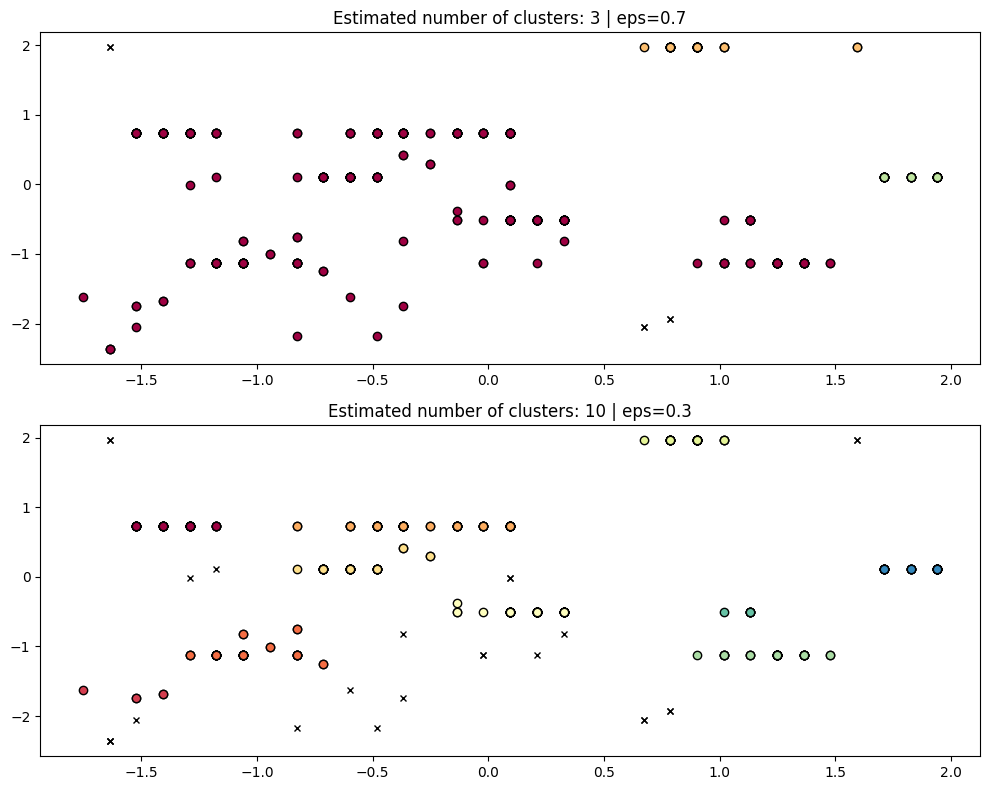

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X_multi)
plot(X_multi, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X_multi)
plot(X_multi, dbs.labels_, parameters=params, ax=axes[1])

Jalankan DBSCAN

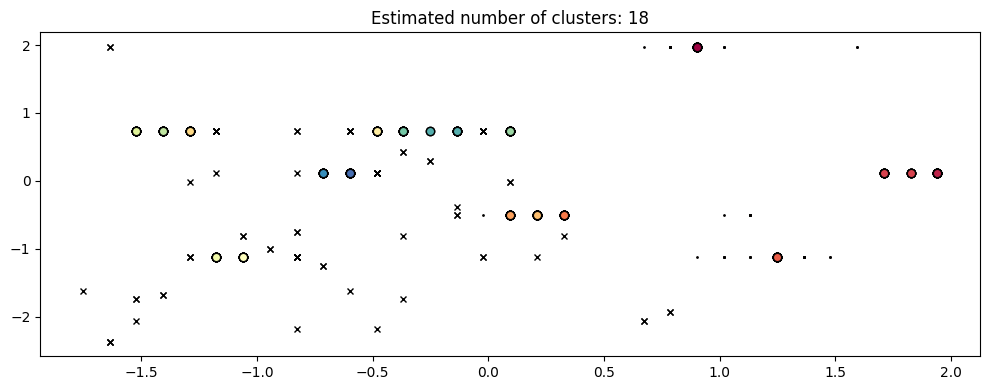

In [10]:
hdb = hdbscan.HDBSCAN(min_cluster_size=10).fit(X_multi)
plot(X_multi, hdb.labels_, hdb.probabilities_)